In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def calcular_mu(vs, rho):
    """
    Calcula el segundo parámetro de Lamé (mu).

    Parámetros
    ----------
    vs : numpy.ndarray
        Matriz de velocidad S [m/s].

    rho : numpy.ndarray o float
        Matriz de densidad [kg/m³] o un valor constante.

    Retorna
    -------
    mu : numpy.ndarray
        Matriz del parámetro de Lamé mu [Pa].
    """

    vs = np.asarray(vs)
    rho = np.asarray(rho)

    mu = rho * vs**2

    return mu

In [3]:
def calcular_lambda(vp, vs, rho):
    """
    Calcula el primer parámetro de Lamé (lambda).

    Parámetros
    ----------
    vp : numpy.ndarray
        Matriz de velocidad P [m/s].

    vs : numpy.ndarray
        Matriz de velocidad S [m/s].

    rho : numpy.ndarray o float
        Matriz de densidad [kg/m³] o valor constante.

    Retorna
    -------
    lambda_ : numpy.ndarray
        Matriz del parámetro de Lamé lambda [Pa].
    """

    vp = np.asarray(vp)
    vs = np.asarray(vs)
    rho = np.asarray(rho)

    lambda_ = rho * (vp**2 - 2 * vs**2)

    return lambda_

In [4]:
def calcular_impedancia_P(vp, rho):
    """
    Calcula las impedancias sísmicas P y S.

    Parámetros
    ----------
    vp : numpy.ndarray
        Matriz de velocidad P [m/s].


    rho : numpy.ndarray o float
        Matriz de densidad [kg/m³] o valor constante.

    Retorna
    -------
    Ip : numpy.ndarray
        Impedancia P [kg/(m²·s)].

    """

    vp = np.asarray(vp)
    rho = np.asarray(rho)

    Ip = rho * vp

    return Ip

In [ ]:
def calcular_impedancia_S(vs, rho):
    """
    Calcula las impedancias sísmicas P y S.

    Parámetros
    ----------

    vs : numpy.ndarray
        Matriz de velocidad S [m/s].

    rho : numpy.ndarray o float
        Matriz de densidad [kg/m³] o valor constante.

    Retorna
    -------

    Is : numpy.ndarray
        Impedancia S [kg/(m²·s)].
    """
    vs = np.asarray(vs)
    rho = np.asarray(rho)

    Is = rho * vs

    return Is

In [ ]:
def calcular_Rps(vp, vs):
    """
    Calcula razón Vp/Vs

    Parámetros
    ----------
    vp : numpy.ndarray
        Matriz de velocidad P [m/s].

    vs : numpy.ndarray
        Matriz de velocidad S [m/s].

    Retorna
    -------
    Rps : numpy.ndarray
        Razon Vp/Vs.

    """

    vp = np.asarray(vp)
    vs = np.asarray(vs)

    Rps = vp / vs

    return Rps

In [5]:
def open_model(path, nx=520, ny=270):
    data = np.fromfile(path, dtype=np.float32).reshape(nx, ny)
    data = data.T

    return data

In [6]:
filename_vp = "Experimento_1_gaussiana/modelvp.bin"
filename_vs = "Experimento_1_gaussiana/modelvs.bin"
filename_rho = "Experimento_1_gaussiana/modelrho.bin"

vp = open_model(filename_vp)
vs = open_model(filename_vs)
rho = open_model(filename_rho)

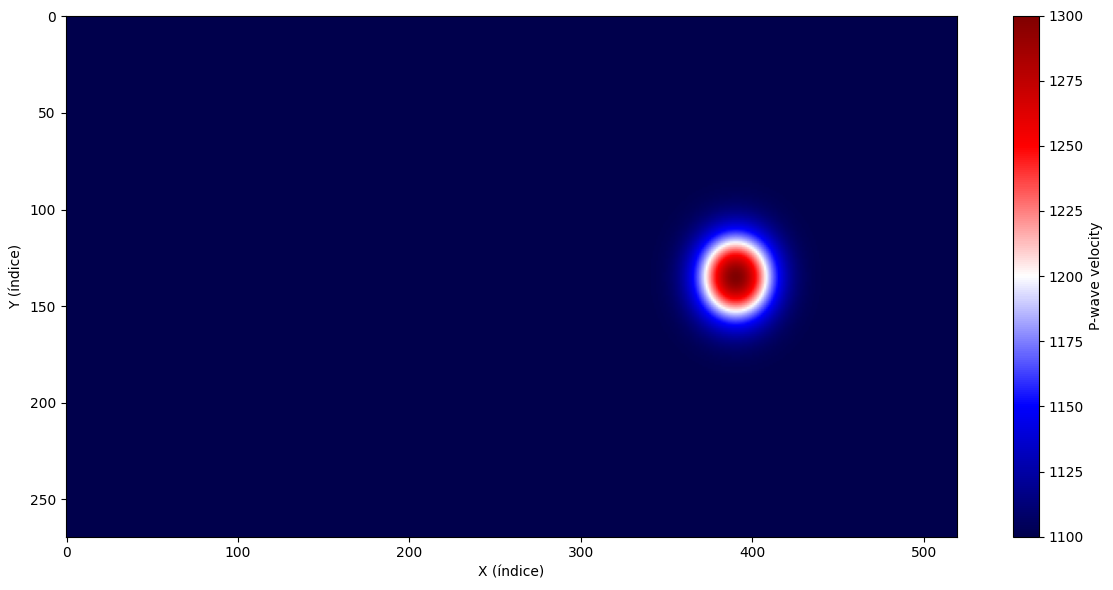

In [8]:
plt.figure(figsize=(12, 6))
plt.imshow(rho, cmap="seismic", aspect="auto", origin="upper")
plt.colorbar(label="P-wave velocity")
# plt.title(f"Campo de presión — t = {t:.3f} s")
plt.xlabel("X (índice)")
plt.ylabel("Y (índice)")
plt.tight_layout()
plt.show()

In [9]:
mu = calcular_mu(vs, rho)
lam = calcular_lambda(vp, vs, rho)

Ip,Is = calcular_impedancias(vp, vs, rho)

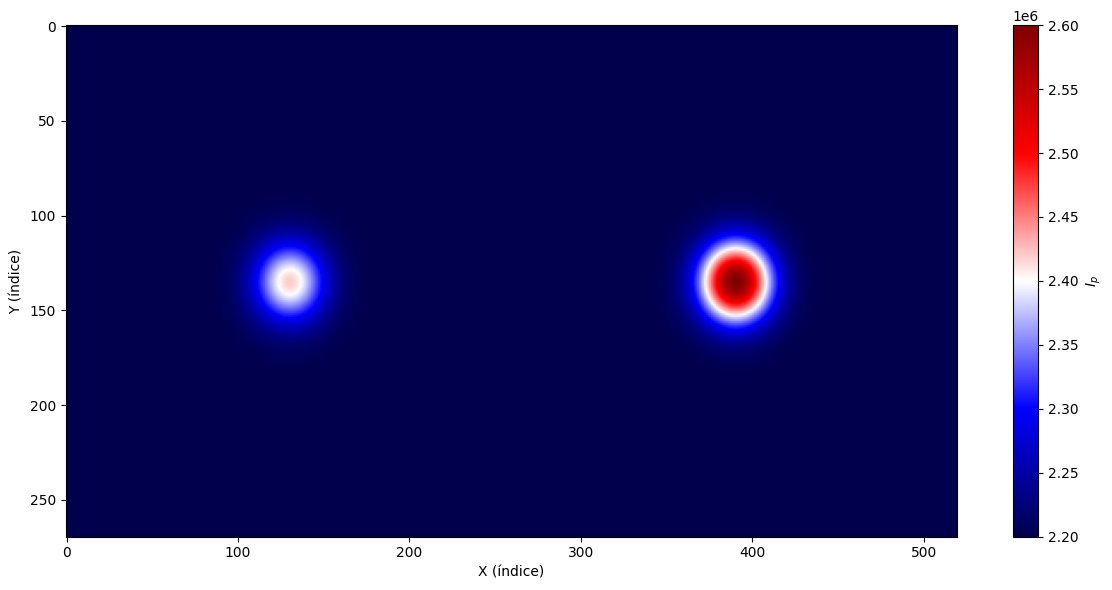

In [10]:
plt.figure(figsize=(12, 6))
plt.imshow(Ip, cmap="seismic", aspect="auto", origin="upper")
# plt.colorbar(label=r"$\mu$")
plt.colorbar(label=r"$I_p$")
# plt.title(f"Campo de presión — t = {t:.3f} s")
plt.xlabel("X (índice)")
plt.ylabel("Y (índice)")
plt.tight_layout()
plt.show()

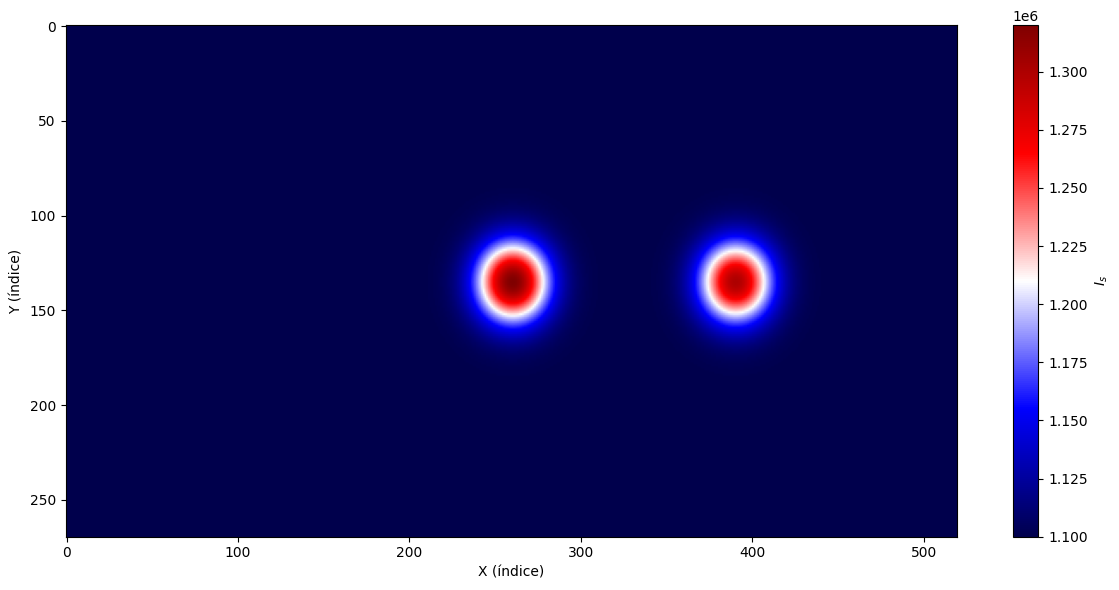

In [11]:
plt.figure(figsize=(12, 6))
plt.imshow(Is, cmap="seismic", aspect="auto", origin="upper")
plt.colorbar(label=r"$I_s$")
# plt.title(f"Campo de presión — t = {t:.3f} s")
plt.xlabel("X (índice)")
plt.ylabel("Y (índice)")
plt.tight_layout()
plt.show()

In [13]:
# np.transpose(Is).astype('float32').tofile('Experimento_1_gaussiana/model_is.bin')